# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
import os

csv_path = "/content/Lab_11_QnA_Dataset_Download.csv"
if not os.path.exists(csv_path):
    csv_path = "Lab_11_QnA_Dataset.csv"

df = pd.read_csv(csv_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

print("X shape:", tuple(X.shape))
print("y shape:", tuple(y.shape))

X shape: (168, 11)
y shape: (168,)


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        out, _ = self.rnn(self.emb(x))                  # (batch, words, 32)
        scores = self.att(out).squeeze(-1)              # (batch, words)
        scores = scores.masked_fill(x == 0, -1e9)       # ignore padding words
        weights = torch.softmax(scores, dim=1)          # attention weights
        context = (out * weights.unsqueeze(-1)).sum(1)  # (batch, 32)
        return self.fc(context), weights

model = RNN()

print(model)

RNN(
  (emb): Embedding(227, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()                                         # clear old gradients
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)                 # calculate loss
    loss.backward()                                               # backpropagation
    optimizer.step()                                              # update parameters

with torch.no_grad():
    acc = (model(X)[0].argmax(1) == y).float().mean().item()
print("Training finished! Final loss:", round(loss.item(), 4))
print("Training accuracy:", round(acc * 100, 1), "%")

Training finished! Final loss: 0.0688
Training accuracy: 98.8 %


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

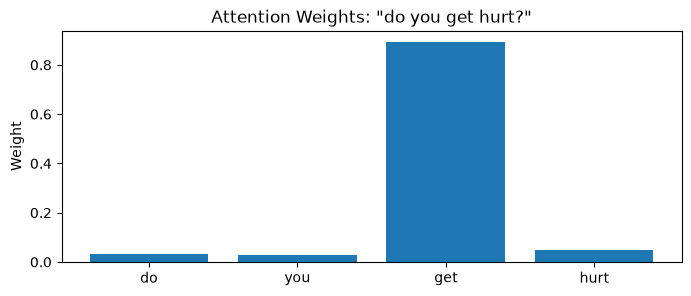

Question: do you get hurt?
Predicted answer: I don't have a body.
Highest attention word: get 0.893
--------------------------------------------------


(['do', 'you', 'get', 'hurt'],
 [0.030628375709056854,
  0.028383124619722366,
  0.8931487798690796,
  0.04783971235156059])

In [6]:
def show_attention(question_text):
    # Tokenize the question the same way as training (lowercase, no punctuation)
    seq = tokenizer.texts_to_sequences([question_text.lower()])[0]
    words = [tokenizer.index_word[i] for i in seq]
    x = torch.tensor([seq], dtype=torch.long)

    with torch.no_grad():
        prediction, weights = model(x)

    w = weights[0].tolist()
    answer_id = prediction.argmax(1).item()
    answer = df.loc[df["answer_id"] == answer_id, "answer"].iloc[0]

    plt.figure(figsize=(8, 3))
    plt.bar(words, w)
    plt.title(f'Attention Weights: "{question_text}"')
    plt.ylabel("Weight")
    plt.show()

    best = max(range(len(words)), key=lambda i: w[i])
    print("Question:", question_text)
    print("Predicted answer:", answer)
    print("Highest attention word:", words[best], round(w[best], 3))
    print("-" * 50)
    return words, w

show_attention(df["question"][0])

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

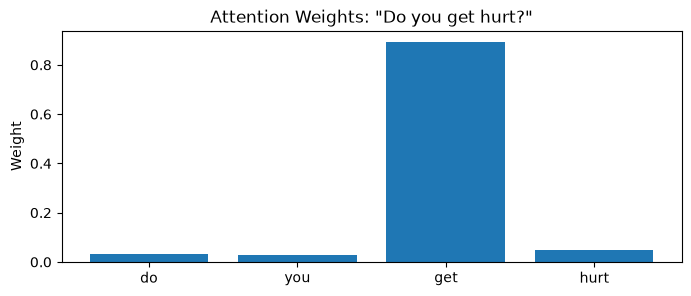

Question: Do you get hurt?
Predicted answer: I don't have a body.
Highest attention word: get 0.893
--------------------------------------------------


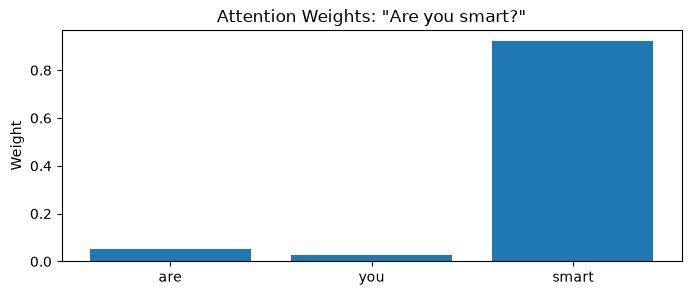

Question: Are you smart?
Predicted answer: I do what I can.
Highest attention word: smart 0.921
--------------------------------------------------


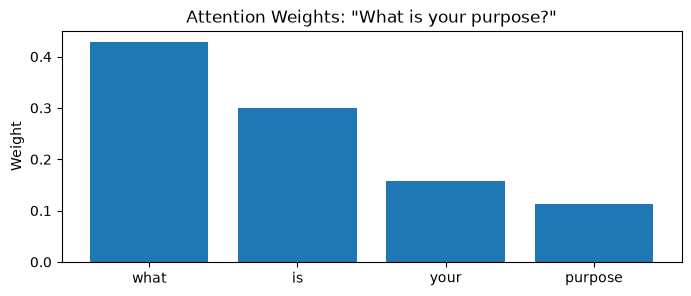

Question: What is your purpose?
Predicted answer: I'm here to answer your questions and help out.
Highest attention word: what 0.429
--------------------------------------------------


In [7]:
for q in ["Do you get hurt?", "Are you smart?", "What is your purpose?"]:
    show_attention(q)

**Answer:** The highest-weight words were 'get' (0.89) for 'Do you get hurt?' and 'smart' (0.92) for 'Are you smart?'. In both, the top word is a key content word of the question, so the attention looks sensible. For 'What is your purpose?' the top weight went to 'what' (0.43), not 'purpose', so the model focused on a common question word here. The weights are learned only from the answer-classification task, so a high weight shows what the model used to decide, not necessarily what a person would consider most important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

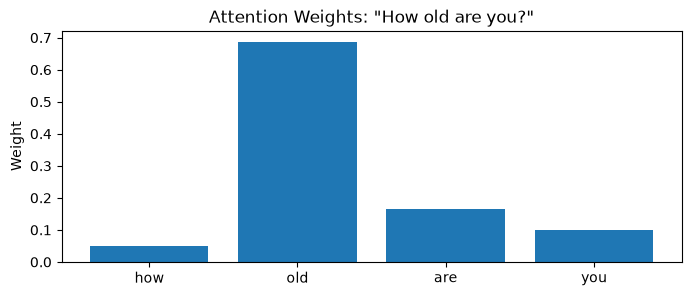

Question: How old are you?
Predicted answer: Age doesn't really apply to me.
Highest attention word: old 0.687
--------------------------------------------------


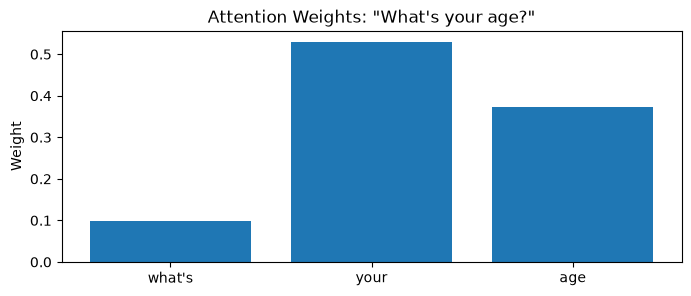

Question: What's your age?
Predicted answer: Age doesn't really apply to me.
Highest attention word: your 0.53
--------------------------------------------------


In [8]:
for q in ["How old are you?", "What's your age?"]:
    show_attention(q)

**Answer:** Both questions get the same answer group (answer_id 1) but focus on different words. 'How old are you?' puts the highest weight on 'old' (0.69), which carries the meaning. 'What's your age?' puts it on 'your' (0.53), not 'age'. So the model attends to different words for similar meanings. Attention here depends on patterns in the small training set (168 questions, 12 answer groups), not only on the meaning of each word.